In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
import matplotlib.pyplot as plt

data = pd.read_csv('../heart_statlog_cleveland_hungary_final.csv')

print("First 5 rows of data:")
data.head()

First 5 rows of data:


,age,sex,chest_pain_type,resting_bp_s,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,ST_slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


In [2]:
print("\nSummary Statistics:")
print(data.describe())
print("\nData Structure:")
print(data.info())


Summary Statistics:
               age          sex  chest_pain_type  resting_bp_s  cholesterol  \
count  1190.000000  1190.000000      1190.000000   1190.000000  1190.000000   
mean     53.720168     0.763866         3.232773    132.153782   210.363866   
std       9.358203     0.424884         0.935480     18.368823   101.420489   
min      28.000000     0.000000         1.000000      0.000000     0.000000   
25%      47.000000     1.000000         3.000000    120.000000   188.000000   
50%      54.000000     1.000000         4.000000    130.000000   229.000000   
75%      60.000000     1.000000         4.000000    140.000000   269.750000   
max      77.000000     1.000000         4.000000    200.000000   603.000000   

       fasting_blood_sugar  resting_ecg  max_heart_rate  exercise_angina  \
count          1190.000000  1190.000000     1190.000000      1190.000000   
mean              0.213445     0.698319      139.732773         0.387395   
std               0.409912     0.870359

In [3]:
print(f"\nOriginal shape: {data.shape}")
duplicated_rows = data[data.duplicated()]
print(f"Duplicate rows found: {len(duplicated_rows)}")
data = data.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {data.shape}")


Original shape: (1190, 12)
Duplicate rows found: 272
Shape after removing duplicates: (918, 12)


In [4]:
print("\nMissing values per column:")
print(data.isnull().sum())


Missing values per column:
age                    0
sex                    0
chest_pain_type        0
resting_bp_s           0
cholesterol            0
fasting_blood_sugar    0
resting_ecg            0
max_heart_rate         0
exercise_angina        0
oldpeak                0
ST_slope               0
target                 0
dtype: int64


In [5]:
print("Missing values per column:")
print(data.isnull().sum())

# Numerical → mean
data.fillna(data.mean(numeric_only=True), inplace=True)

# Categorical → mode
data.fillna(data.mode().iloc[0], inplace=True)

Missing values per column:
age                    0
sex                    0
chest_pain_type        0
resting_bp_s           0
cholesterol            0
fasting_blood_sugar    0
resting_ecg            0
max_heart_rate         0
exercise_angina        0
oldpeak                0
ST_slope               0
target                 0
dtype: int64


,age,sex,chest_pain_type,resting_bp_s,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,ST_slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,1,1,110,264,0,0,132,0,1.2,2,1
914,68,1,4,144,193,1,0,141,0,3.4,2,1
915,57,1,4,130,131,0,0,115,1,1.2,2,1
916,57,0,2,130,236,0,2,174,0,0.0,2,1


In [6]:
categorical_columns = [
    'sex',
    'chest_pain_type',
    'fasting_blood_sugar',
    'resting_ecg',
    'exercise_angina',
    'ST_slope'
]

data = pd.get_dummies(data, columns=categorical_columns, drop_first=True)

print("Shape after encoding:", data.shape)

Shape after encoding: (918, 17)


In [7]:
data.head(5)

,age,resting_bp_s,cholesterol,max_heart_rate,oldpeak,target,sex_1,chest_pain_type_2,chest_pain_type_3,chest_pain_type_4,fasting_blood_sugar_1,resting_ecg_1,resting_ecg_2,exercise_angina_1,ST_slope_1,ST_slope_2,ST_slope_3
0,40,140,289,172,0.0,0,True,True,False,False,False,False,False,False,True,False,False
1,49,160,180,156,1.0,1,False,False,True,False,False,False,False,False,False,True,False
2,37,130,283,98,0.0,0,True,True,False,False,False,True,False,False,True,False,False
3,48,138,214,108,1.5,1,False,False,False,True,False,False,False,True,False,True,False
4,54,150,195,122,0.0,0,True,False,True,False,False,False,False,False,True,False,False


In [8]:
large_scale_features = ['age', 'resting_bp_s', 'cholesterol', 'oldpeak']

for col in large_scale_features:
    
    mu = data[col].mean() 
    sigma = data[col].std() 
    
    data[col] = (data[col] - mu) / sigma

print("After Standardization:")
print(data[large_scale_features].head())

After Standardization:
        age  resting_bp_s  cholesterol   oldpeak
0 -1.432359      0.410685     0.824621 -0.831979
1 -0.478223      1.490940    -0.171867  0.105606
2 -1.750404     -0.129442     0.769768 -0.831979
3 -0.584238      0.302660     0.138964  0.574398
4  0.051853      0.950812    -0.034736 -0.831979


In [9]:
numerical_columns = data.select_dtypes(include=['int64', 'float64']).columns
numerical_columns = numerical_columns.drop('target')

for col in numerical_columns:
    
    xmin = data[col].min()
    xmax = data[col].max()
    
    data[col] = (data[col] - xmin) / (xmax - xmin)

print("After Min-Max Normalization:")
data[numerical_columns].head()

After Min-Max Normalization:


,age,resting_bp_s,cholesterol,max_heart_rate,oldpeak
0,0.244898,0.70,0.479270,0.788732,0.295455
1,0.428571,0.80,0.298507,0.676056,0.409091
2,0.183673,0.65,0.469320,0.267606,0.295455
3,0.408163,0.69,0.354892,0.338028,0.465909
4,0.530612,0.75,0.323383,0.436620,0.295455


In [10]:
data.head()

,age,resting_bp_s,cholesterol,max_heart_rate,oldpeak,target,sex_1,chest_pain_type_2,chest_pain_type_3,chest_pain_type_4,fasting_blood_sugar_1,resting_ecg_1,resting_ecg_2,exercise_angina_1,ST_slope_1,ST_slope_2,ST_slope_3
0,0.244898,0.70,0.479270,0.788732,0.295455,0,True,True,False,False,False,False,False,False,True,False,False
1,0.428571,0.80,0.298507,0.676056,0.409091,1,False,False,True,False,False,False,False,False,False,True,False
2,0.183673,0.65,0.469320,0.267606,0.295455,0,True,True,False,False,False,True,False,False,True,False,False
3,0.408163,0.69,0.354892,0.338028,0.465909,1,False,False,False,True,False,False,False,True,False,True,False
4,0.530612,0.75,0.323383,0.436620,0.295455,0,True,False,True,False,False,False,False,False,True,False,False


In [11]:
X = data.drop("target", axis=1)
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (734, 16)
Test shape: (184, 16)


In [12]:
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.model_selection import cross_val_score, StratifiedKFold

rf_model = RandomForestClassifier(
    criterion='gini',
    max_depth=8,
    max_features='sqrt',
    n_estimators=200,
    random_state=42,
)

knn_model = KNeighborsClassifier(
    n_neighbors=11,
    algorithm = 'auto',
    p =  2,
    weights = 'distance'
)

lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=20,
    random_state=42,
    solver='liblinear',
)

nb_model = GaussianNB(
    var_smoothing=0.8111308307896871,

)

gb_model = GradientBoostingClassifier(
    learning_rate=0.1,
    max_depth=2,
    n_estimators=50,
    random_state=42,
)

ab_model = AdaBoostClassifier(
    learning_rate=1,
    n_estimators=100,
    random_state=42,
)
from sklearn.ensemble import VotingClassifier

soft_voting_clf = VotingClassifier(
    estimators=[
        ('random_forest', rf_model),
        ('knn', knn_model),
        ('logistic_regression', lr_model),
        ('naive_bayes', nb_model),
        ('gradient_boosting', gb_model),
        ('adaboost', ab_model)
    ],
    voting='soft', 
    weights=None
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(soft_voting_clf, X_train, y_train, cv=cv, scoring='accuracy')

print(f"CV Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)")

soft_voting_clf.fit(X_train, y_train)
y_pred = soft_voting_clf.predict(X_test)
y_proba = soft_voting_clf.predict_proba(X_test)[:, 1]

CV Scores: [0.86394558 0.78911565 0.8707483  0.88435374 0.89041096]
Mean CV Accuracy: 85.97% (+/- 3.65%)


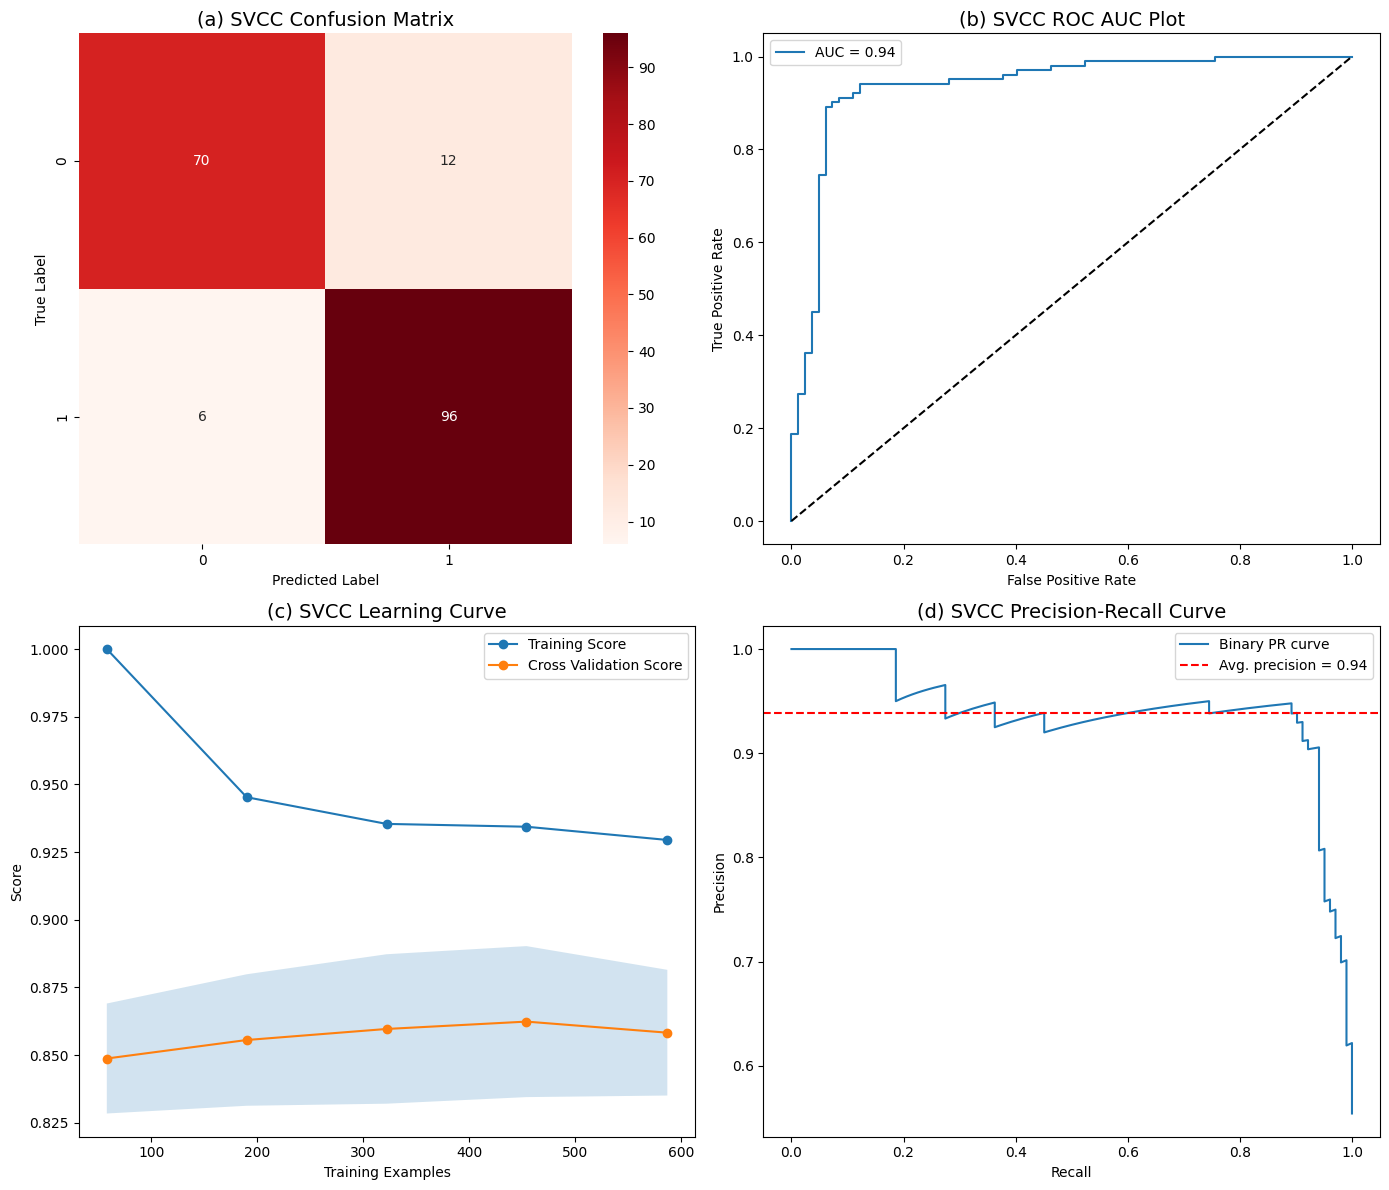

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
from sklearn.model_selection import learning_curve

y_pred = soft_voting_clf.predict(X_test)
y_proba = soft_voting_clf.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Reds',
    ax=axes[0, 0]
)

axes[0, 0].set_title("(a) SVCC Confusion Matrix", fontsize=14)
axes[0, 0].set_xlabel("Predicted Label")
axes[0, 0].set_ylabel("True Label")

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

axes[0, 1].plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
axes[0, 1].plot([0, 1], [0, 1], 'k--')
axes[0, 1].set_title("(b) SVCC ROC AUC Plot", fontsize=14)
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend()

# Learning Curve
train_sizes, train_scores, val_scores = learning_curve(
    soft_voting_clf,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

axes[1, 0].plot(train_sizes, train_mean, 'o-', label="Training Score")
axes[1, 0].plot(train_sizes, val_mean, 'o-', label="Cross Validation Score")
axes[1, 0].fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)

axes[1, 0].set_title("(c) SVCC Learning Curve", fontsize=14)
axes[1, 0].set_xlabel("Training Examples")
axes[1, 0].set_ylabel("Score")
axes[1, 0].legend()

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_proba)
avg_precision = average_precision_score(y_test, y_proba)

axes[1, 1].plot(recall, precision, label="Binary PR curve")
axes[1, 1].axhline(y=avg_precision, linestyle='--', color='r',
                   label=f"Avg. precision = {avg_precision:.2f}")

axes[1, 1].set_title("(d) SVCC Precision-Recall Curve", fontsize=14)
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_ylabel("Precision")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

precision_val = precision_score(y_test, y_pred)
recall_val = recall_score(y_test, y_pred)
f1_val = f1_score(y_test, y_pred)
accuracy_val = accuracy_score(y_test, y_pred)

print(f"Precision: {precision_val*100:.2f}%")
print(f"Recall: {recall_val*100:.2f}%")
print(f"F1 Score: {f1_val*100:.2f}%")
print(f"Accuracy: {accuracy_val*100:.2f}%")
print(f"Accuracy Loss: {(1-accuracy_val)*100:.2f}%")

Precision: 88.89%
Recall: 94.12%
F1 Score: 91.43%
Accuracy: 90.22%
Accuracy Loss: 9.78%


In [15]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import StackingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
import warnings
warnings.filterwarnings('ignore')

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)

param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 2, 3]
}

search_xgb = RandomizedSearchCV(
    xgb,
    param_distributions=param_grid_xgb,
    n_iter=20,
    cv=cv,
    scoring='recall',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

search_xgb.fit(X_train, y_train)
best_xgb = search_xgb.best_estimator_
print(f"Best XGBoost params: {search_xgb.best_params_}")
print(f"Best XGBoost score: {search_xgb.best_score_:.4f}")

cat = CatBoostClassifier(
    iterations=200,
    learning_rate=0.05,
    depth=4,
    l2_leaf_reg=3,
    random_seed=42,
    verbose=0,
    early_stopping_rounds=50
)


stack = StackingClassifier(
    estimators=[
        ('xgb', best_xgb),
        ('random_forest', rf_model),
        ('knn', knn_model),
        ('cat',cat),
        ('logistic_regression', lr_model),
        ('naive_bayes', nb_model),
        ('gradient_boosting', gb_model),
        ('adaboost', ab_model),
        ('sve',soft_voting_clf)
    ],
    final_estimator=LogisticRegression(C=2, max_iter=1000),
    cv=cv,
    n_jobs=-1
)
stack.fit(X_train, y_train)

y_pred_stack = stack.predict(X_test)
y_proba_stack = stack.predict_proba(X_test)[:, 1]

stack_accuracy = accuracy_score(y_test, y_pred_stack)
stack_precision = precision_score(y_test, y_pred_stack)
stack_recall = recall_score(y_test, y_pred_stack)
stack_f1 = f1_score(y_test, y_pred_stack)

print(f"\n Stacking Model Results:")
print(f"Accuracy:  {stack_accuracy*100:.2f}%")
print(f"Precision: {stack_precision*100:.2f}%")
print(f"Recall:    {stack_recall*100:.2f}%")
print(f"F1 Score:  {stack_f1*100:.2f}%")

Fitting 10 folds for each of 20 candidates, totalling 200 fits
Best XGBoost params: {'subsample': 0.8, 'reg_lambda': 2, 'reg_alpha': 1, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
Best XGBoost score: 0.9190

 Stacking Model Results:
Accuracy:  89.67%
Precision: 90.29%
Recall:    91.18%
F1 Score:  90.73%


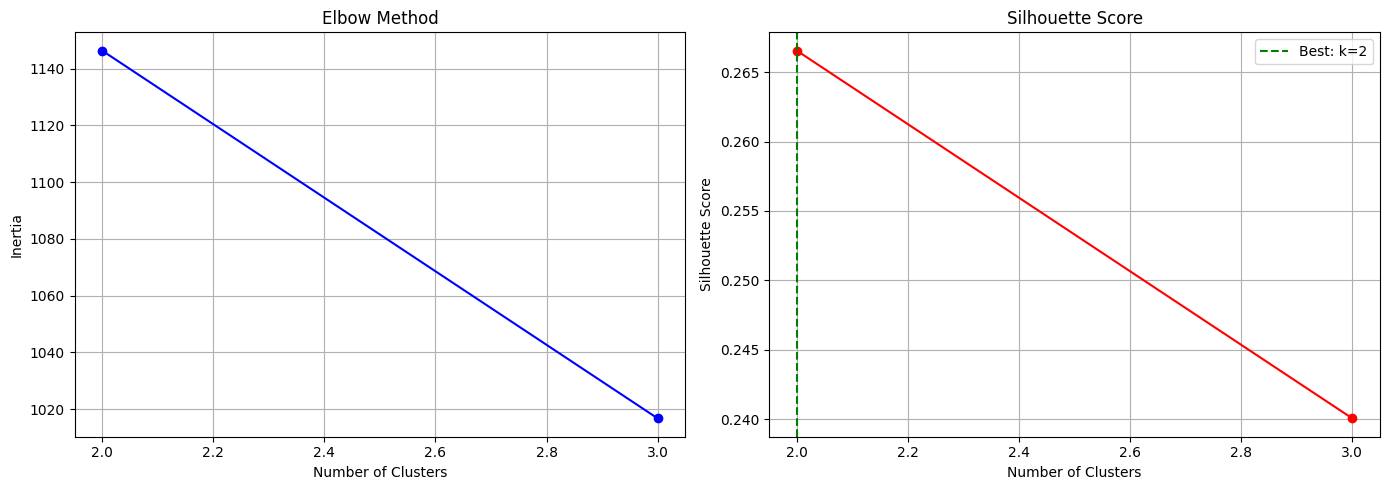

Best number of clusters: 2


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings('ignore')
inertias = []
silhouette_scores = []
K_range = range(2, 4)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_train)
    inertias.append(kmeans.inertia_)
    if len(np.unique(labels)) > 1:
        silhouette_scores.append(silhouette_score(X_train, labels))
    else:
        silhouette_scores.append(-1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertias, 'bo-')
axes[0].set_xlabel('Number of Clusters')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')
axes[0].grid(True)

axes[1].plot(K_range, silhouette_scores, 'ro-')
axes[1].set_xlabel('Number of Clusters')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score')
axes[1].grid(True)
best_k = K_range[np.argmax(silhouette_scores)]
axes[1].axvline(x=best_k, color='green', linestyle='--', label=f'Best: k={best_k}')
axes[1].legend()

plt.tight_layout()
plt.show()
print(f"Best number of clusters: {best_k}")

In [17]:
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
train_clusters = kmeans.fit_predict(X_train)
test_clusters = kmeans.predict(X_test)
models = {
    'RandomForest': RandomForestClassifier(
        criterion='gini', max_depth=8, max_features='sqrt', 
        n_estimators=200, random_state=42
    ),
    'KNN': KNeighborsClassifier(n_neighbors=3),
    'LogisticRegression': LogisticRegression(
        class_weight='balanced', max_iter=20, 
        random_state=42, solver='liblinear'
    ),
    'GaussianNB': GaussianNB(var_smoothing=0.8111308307896871),
    'AdaBoost': AdaBoostClassifier(
        learning_rate=0.1, n_estimators=100, random_state=42
    ),
    'GradientBoosting': GradientBoostingClassifier(
        learning_rate=0.2, max_depth=3, 
        n_estimators=50, random_state=42
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)

voting_model = VotingClassifier(
    estimators=[(name.lower(), model) for name, model in models.items()],
    voting='soft'
)
voting_model.fit(X_train, y_train)

for cluster_id in range(n_clusters):
    test_mask = test_clusters == cluster_id
    if np.sum(test_mask) == 0:
        print(f"\nCluster {cluster_id}: No test samples")
        continue
        
    X_test_cluster = X_test[test_mask]
    y_test_cluster = y_test[test_mask]
    
    print(f"\n Cluster {cluster_id} - {np.sum(test_mask)} test samples")
    
    for name, model in models.items():
        y_pred = model.predict(X_test_cluster)
        acc = accuracy_score(y_test_cluster, y_pred)
        print(f"  {name:20s}: {acc*100:.2f}%")
    
    y_pred_voting = voting_model.predict(X_test_cluster)
    acc_voting = accuracy_score(y_test_cluster, y_pred_voting)
    print(f"  {'Soft Voting':20s}: {acc_voting*100:.2f}%")

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{name:20s}: {acc*100:.2f}%")

y_pred_voting = voting_model.predict(X_test)
acc_voting = accuracy_score(y_test, y_pred_voting)
print(f"{'Soft Voting':20s}: {acc_voting*100:.2f}%")


 Cluster 0 - 54 test samples
  RandomForest        : 88.89%
  KNN                 : 90.74%
  LogisticRegression  : 90.74%
  GaussianNB          : 90.74%
  AdaBoost            : 88.89%
  GradientBoosting    : 92.59%
  Soft Voting         : 88.89%

 Cluster 1 - 55 test samples
  RandomForest        : 96.36%
  KNN                 : 92.73%
  LogisticRegression  : 92.73%
  GaussianNB          : 92.73%
  AdaBoost            : 92.73%
  GradientBoosting    : 94.55%
  Soft Voting         : 94.55%

 Cluster 2 - 37 test samples
  RandomForest        : 83.78%
  KNN                 : 89.19%
  LogisticRegression  : 86.49%
  GaussianNB          : 89.19%
  AdaBoost            : 91.89%
  GradientBoosting    : 83.78%
  Soft Voting         : 91.89%

 Cluster 3 - 38 test samples
  RandomForest        : 81.58%
  KNN                 : 76.32%
  LogisticRegression  : 84.21%
  GaussianNB          : 84.21%
  AdaBoost            : 81.58%
  GradientBoosting    : 86.84%
  Soft Voting         : 89.47%
RandomForest

In [18]:
models = {
    'Naive Bayes': GaussianNB(var_smoothing=1e-5),
    'KNN': KNeighborsClassifier(
        n_neighbors=11,
        algorithm='auto',
        p=2,
        weights='distance'
    ),
    'AdaBoost': AdaBoostClassifier(
        learning_rate=1,
        n_estimators=100,
        random_state=42,
    ),
    'Random Forest': RandomForestClassifier(
        criterion='gini',
        max_depth=8,
        max_features='sqrt',
        n_estimators=200,
        random_state=42,
    ),
    'Logistic Regression': LogisticRegression(
        class_weight='balanced',
        max_iter=20,
        random_state=42,
        solver='liblinear',
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        learning_rate=0.1,
        max_depth=2,
        n_estimators=50,
        random_state=42,
    ),
}

results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    
    results[name] = accuracy
    print(f"{name:20s} -> CV: {cv_scores.mean()*100:.2f}%, Test: {accuracy*100:.2f}%")


estimators = [(name.lower().replace(' ', '_'), model) for name, model in models.items()]
voting_model = VotingClassifier(estimators=estimators, voting='soft')
voting_model.fit(X_train, y_train)

y_pred_voting = voting_model.predict(X_test)
y_proba_voting = voting_model.predict_proba(X_test)[:, 1]
voting_accuracy = accuracy_score(y_test, y_pred_voting)
print(f"Ensemble Accuracy: {voting_accuracy*100:.2f}%")
print("Simple Fuzzy Logic System")

def simple_fuzzy_decision(prob):
    # Define fuzzy zones
    if prob < 0.3:
        return 0, "Healthy", 1.0
    elif prob > 0.7:
        return 1, "Diseased", 1.0
    else:
        uncertainty = 1 - (abs(prob - 0.5) * 2)
        if prob > 0.5:
            return 1, f"Possibly Diseased (uncertainty: {uncertainty*100:.1f}%)", 1-uncertainty
        else:
            return 0, f"Possibly Healthy (uncertainty: {uncertainty*100:.1f}%)", 1-uncertainty

fuzzy_results = []
for prob in y_proba_voting:
    decision, status, confidence = simple_fuzzy_decision(prob)
    fuzzy_results.append({
        'probability': prob,
        'decision': decision,
        'status': status,
        'confidence': confidence
    })

df_fuzzy = pd.DataFrame(fuzzy_results)
y_pred_fuzzy = df_fuzzy['decision'].values
fuzzy_accuracy = accuracy_score(y_test, y_pred_fuzzy)

needs_review = df_fuzzy[df_fuzzy['status'].str.contains('Possibly')]
print(f"\nFuzzy Accuracy: {fuzzy_accuracy*100:.2f}%")
print(f"Cases needing review: {len(needs_review)} ({len(needs_review)/len(y_test)*100:.1f}%)")


Naive Bayes          -> CV: 84.47%, Test: 87.50%
KNN                  -> CV: 85.70%, Test: 90.22%
AdaBoost             -> CV: 85.29%, Test: 88.04%
Random Forest        -> CV: 85.15%, Test: 88.59%
Logistic Regression  -> CV: 84.06%, Test: 89.13%
Gradient Boosting    -> CV: 86.38%, Test: 89.67%
Ensemble Accuracy: 90.76%
Simple Fuzzy Logic System

Fuzzy Accuracy: 90.76%
Cases needing review: 34 (18.5%)


Creating Visualizations


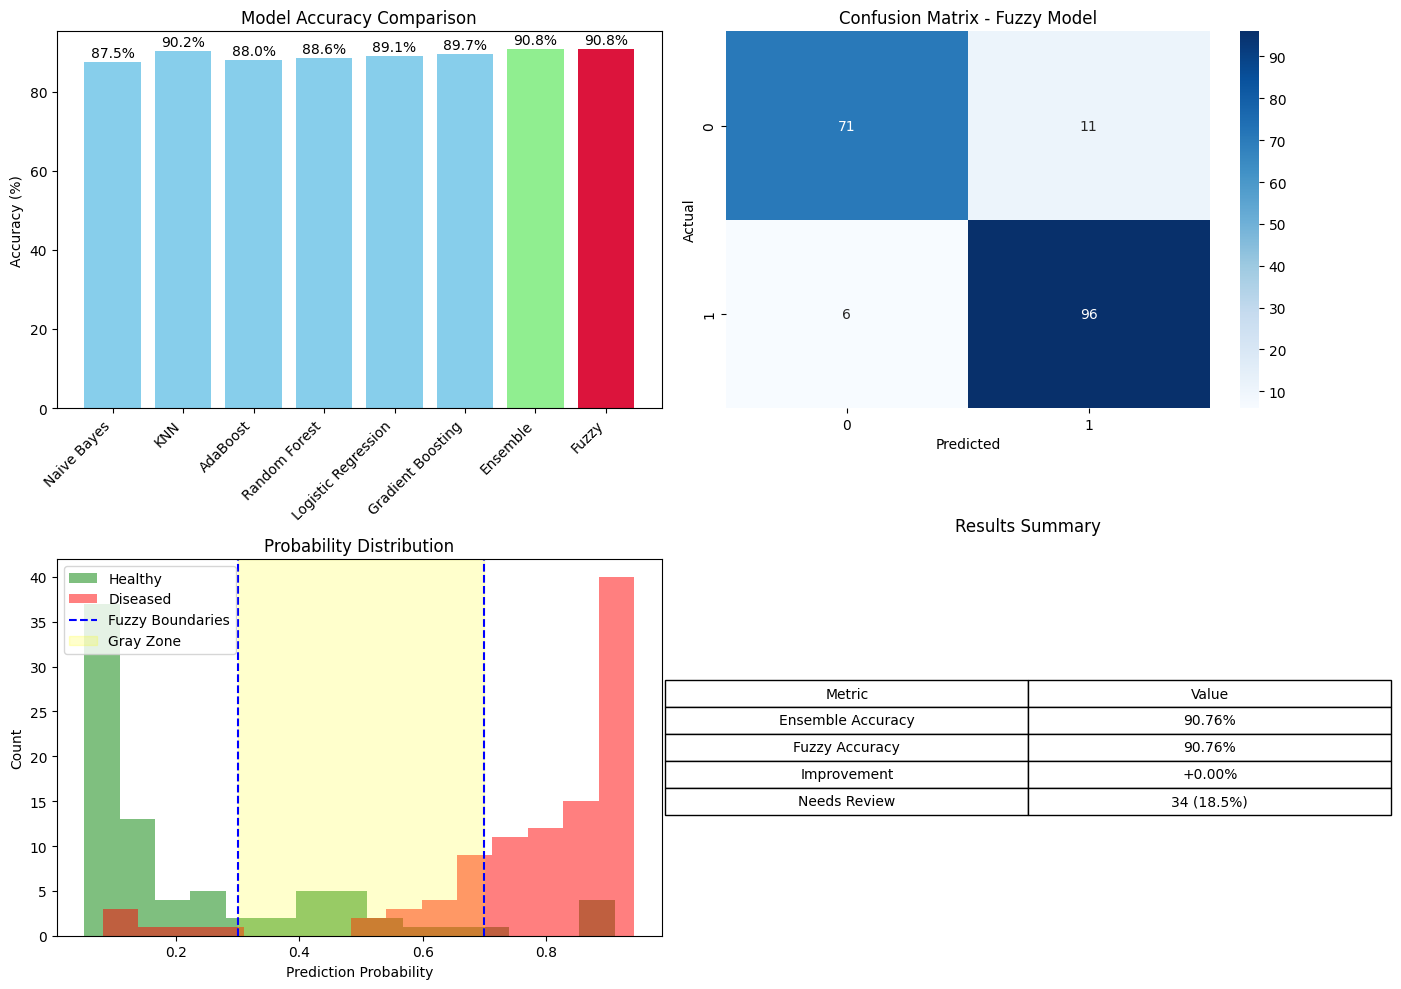


Models Used: 6 classifiers + Ensemble
Ensemble Accuracy: 90.76%
Fuzzy Accuracy: 90.76%
Improvement: +0.00%
Clinical Utility:
- 34 cases (18.5%) need doctor review
- Fuzzy system handles uncertainty better
- More interpretable for medical use



In [19]:
print("Creating Visualizations")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Model Accuracy Comparison
ax1 = axes[0, 0]
model_names = list(results.keys()) + ['Ensemble', 'Fuzzy']
accuracies = [results[name]*100 for name in results.keys()] + [voting_accuracy*100, fuzzy_accuracy*100]
colors = ['skyblue']*6 + ['lightgreen', 'crimson']
bars = ax1.bar(model_names, accuracies, color=colors)
ax1.set_title('Model Accuracy Comparison')
ax1.set_ylabel('Accuracy (%)')
ax1.set_xticklabels(model_names, rotation=45, ha='right')
for bar, acc in zip(bars, accuracies):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{acc:.1f}%', ha='center', va='bottom')

# Fuzzy Confusion Matrix
ax2 = axes[0, 1]
cm = confusion_matrix(y_test, y_pred_fuzzy)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax2)
ax2.set_title('Confusion Matrix - Fuzzy Model')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')

# Probability Distribution with Fuzzy Zones
ax3 = axes[1, 0]
ax3.hist(y_proba_voting[y_test==0], bins=15, alpha=0.5, label='Healthy', color='green')
ax3.hist(y_proba_voting[y_test==1], bins=15, alpha=0.5, label='Diseased', color='red')
ax3.axvline(x=0.3, color='blue', linestyle='--', label='Fuzzy Boundaries')
ax3.axvline(x=0.7, color='blue', linestyle='--')
ax3.axvspan(0.3, 0.7, alpha=0.2, color='yellow', label='Gray Zone')
ax3.set_title('Probability Distribution')
ax3.set_xlabel('Prediction Probability')
ax3.set_ylabel('Count')
ax3.legend()

# Summary Table
ax4 = axes[1, 1]
ax4.axis('tight')
ax4.axis('off')
summary_data = [
    ['Metric', 'Value'],
    ['Ensemble Accuracy', f'{voting_accuracy*100:.2f}%'],
    ['Fuzzy Accuracy', f'{fuzzy_accuracy*100:.2f}%'],
    ['Improvement', f'{(fuzzy_accuracy - voting_accuracy)*100:+.2f}%'],
    ['Needs Review', f'{len(needs_review)} ({len(needs_review)/len(y_test)*100:.1f}%)']
]
table = ax4.table(cellText=summary_data, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)
ax4.set_title('Results Summary', fontsize=12, pad=20)

plt.tight_layout()
plt.show()

print(f"""
Models Used: 6 classifiers + Ensemble
Ensemble Accuracy: {voting_accuracy*100:.2f}%
Fuzzy Accuracy: {fuzzy_accuracy*100:.2f}%
Improvement: {(fuzzy_accuracy - voting_accuracy)*100:+.2f}%
Clinical Utility:
- {len(needs_review)} cases ({len(needs_review)/len(y_test)*100:.1f}%) need doctor review
- Fuzzy system handles uncertainty better
- More interpretable for medical use
""")